<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter4/pinn_1_2_hidden_layer_scaled_jax.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Comparison of 1, 2 hidden layer PINN solution with exact and small angle approximation. Drop angle is $\pi/4=45^{\circ}$


--- Training 1-Layer PINN (97 params) ---


/tmp/ipykernel_2599/1450237245.py:133: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Training Complete in 6.47s! Final Loss: 0.003411

--- Training 2-Layer PINN (1,153 params) ---
Training Complete in 30.57s! Final Loss: 0.000210


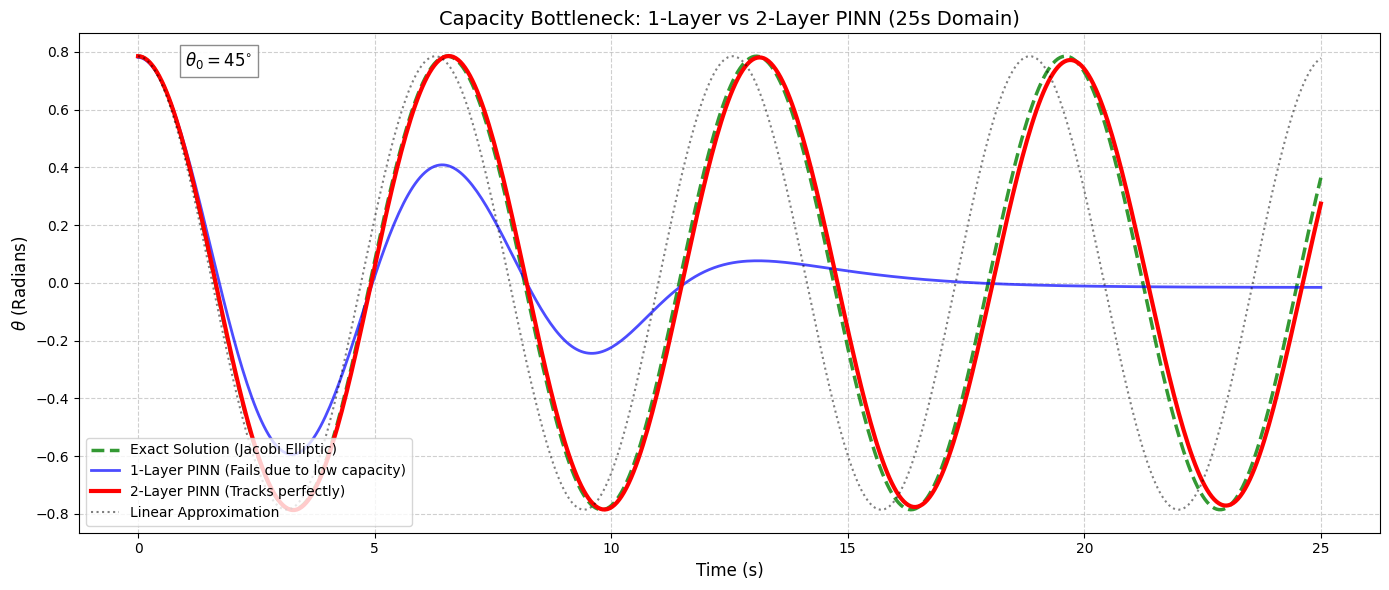

In [6]:
import jax
# CRITICAL: Configure x64 BEFORE importing jnp!
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
from jax import jit, value_and_grad, grad, vmap
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import scipy.special as sp
import time

# ==========================================
# 1-Layer Architecture (Position Only)
# ==========================================
def unpack_weights_1L(params, H):
    idx = 0
    W1 = params[idx : idx+H].reshape(1, H); idx += H
    b1 = params[idx : idx+H].reshape(1, H); idx += H
    W2 = params[idx : idx+H].reshape(H, 1); idx += H
    b2 = params[idx : idx+1].reshape(1, 1)
    return W1, b1, W2, b2

def pack_weights_1L(W1, b1, W2, b2):
    return np.concatenate([W1.flatten(), b1.flatten(), W2.flatten(), b2.flatten()])

def predict_1L(params, t_scalar, H):
    W1, b1, W2, b2 = unpack_weights_1L(params, H)
    tau = t_scalar / 25.0
    a = jnp.tanh(jnp.dot(tau, W1) + b1)
    theta = jnp.dot(a, W2) + b2
    return theta[0, 0]

# ==========================================
# 2-Layer Architecture (Position Only)
# ==========================================
def unpack_weights_2L(params, H):
    idx = 0
    W1 = params[idx : idx+H].reshape(1, H); idx += H
    b1 = params[idx : idx+H].reshape(1, H); idx += H
    W2 = params[idx : idx+H*H].reshape(H, H); idx += H*H
    b2 = params[idx : idx+H].reshape(1, H); idx += H
    W3 = params[idx : idx+H].reshape(H, 1); idx += H
    b3 = params[idx : idx+1].reshape(1, 1)
    return W1, b1, W2, b2, W3, b3

def pack_weights_2L(W1, b1, W2, b2, W3, b3):
    return np.concatenate([
        W1.flatten(), b1.flatten(),
        W2.flatten(), b2.flatten(),
        W3.flatten(), b3.flatten()
    ])

def predict_2L(params, t_scalar, H):
    W1, b1, W2, b2, W3, b3 = unpack_weights_2L(params, H)
    tau = t_scalar / 25.0
    a1 = jnp.tanh(jnp.dot(tau, W1) + b1)
    a2 = jnp.tanh(jnp.dot(a1, W2) + b2)
    theta = jnp.dot(a2, W3) + b3
    return theta[0, 0]

# ==========================================
# Universal AutoDiff Loss Builder
# ==========================================
def build_autodiff_loss(predict_func):
    # Let JAX handle the calculus!
    predict_velocity = grad(predict_func, argnums=1)
    predict_acceleration = grad(predict_velocity, argnums=1)

    # Vectorize for mass evaluation
    vmap_theta = vmap(predict_func, in_axes=(None, 0, None))
    vmap_velocity = vmap(predict_velocity, in_axes=(None, 0, None))
    vmap_acceleration = vmap(predict_acceleration, in_axes=(None, 0, None))

    def compute_loss(params, t_domain, t_ic, theta_0, omega_0, H):
        t_flat = t_domain.flatten()
        t_ic_flat = t_ic.flatten()

        # ODE Loss
        theta = vmap_theta(params, t_flat, H)
        acceleration = vmap_acceleration(params, t_flat, H)
        residual = acceleration + jnp.sin(theta)
        loss_ode = jnp.mean(residual**2)

        # IC Loss
        theta_pred_ic = vmap_theta(params, t_ic_flat, H)
        velocity_pred_ic = vmap_velocity(params, t_ic_flat, H)
        loss_ic_position = jnp.mean((theta_pred_ic - theta_0)**2)
        loss_ic_velocity = jnp.mean((velocity_pred_ic - omega_0)**2)

        return loss_ode + loss_ic_position + loss_ic_velocity

    loss_and_grad = jit(value_and_grad(compute_loss), static_argnums=(5,))

    def scipy_objective(params, t_domain, t_ic, theta_0, omega_0, H):
        loss, grads = loss_and_grad(params, t_domain, t_ic, theta_0, omega_0, H)
        return float(loss), np.array(grads)

    return scipy_objective, vmap_theta

loss_1L, vmap_theta_1L = build_autodiff_loss(predict_1L)
loss_2L, vmap_theta_2L = build_autodiff_loss(predict_2L)

# ==========================================
# Training Setup
# ==========================================
H = 32
t_domain = jnp.linspace(0, 25, 500).reshape(-1, 1)
t_ic = jnp.array([[0.0]])
theta_0 = jnp.pi / 4
omega_0 = 0.0

np.random.seed(42)
W1_1L = np.random.randn(1, H) * 10.0
b1_1L = np.zeros((1, H))
W2_1L = np.random.randn(H, 1) * np.sqrt(2.0 / (H + 1))
b2_1L = np.zeros((1, 1))
weights_1L = pack_weights_1L(W1_1L, b1_1L, W2_1L, b2_1L)

np.random.seed(42) # Absolute reset for true 1:1 comparison
W1_2L = np.random.randn(1, H) * 10.0
b1_2L = np.zeros((1, H))
W2_2L = np.random.randn(H, H) * np.sqrt(2.0 / (H + H))
b2_2L = np.zeros((1, H))
W3_2L = np.random.randn(H, 1) * np.sqrt(2.0 / (H + 1))
b3_2L = np.zeros((1, 1))
weights_2L = pack_weights_2L(W1_2L, b1_2L, W2_2L, b2_2L, W3_2L, b3_2L)

def train_network(objective, initial_weights, name):
    print(f"\n--- Training {name} ---")
    start_time = time.time()

    res = minimize(
        fun=objective,
        x0=initial_weights,
        args=(t_domain, t_ic, theta_0, omega_0, H),
        method='L-BFGS-B',
        jac=True,
        options={'maxiter': 10000, 'maxfun': 500000, 'disp': False}
    )

    elapsed = time.time() - start_time
    print(f"Training Complete in {elapsed:.2f}s! Final Loss: {res.fun:.6f}")
    return res.x

final_weights_1L = train_network(loss_1L, weights_1L, "1-Layer PINN (97 params)")
final_weights_2L = train_network(loss_2L, weights_2L, "2-Layer PINN (1,153 params)")

# ==========================================
# Evaluation and Plotting
# ==========================================
t_plot = np.array(t_domain).flatten()
plot_1L = np.array(vmap_theta_1L(final_weights_1L, t_plot, H))
plot_2L = np.array(vmap_theta_2L(final_weights_2L, t_plot, H))

# Exact Solution
k = np.sin(theta_0 / 2)
m = k**2
sn, cn, dn, ph = sp.ellipj(t_plot, m)
exact_solution = 2 * np.arcsin(k * (cn / dn))
linear_solution = theta_0 * np.cos(t_plot)

plt.figure(figsize=(14, 6))
plt.plot(t_plot, exact_solution, 'g--', linewidth=2.5, alpha=0.8, label='Exact Solution (Jacobi Elliptic)')
plt.plot(t_plot, plot_1L, 'b-', linewidth=2, alpha=0.7, label='1-Layer PINN (Fails due to low capacity)')
plt.plot(t_plot, plot_2L, 'r-', linewidth=3, label='2-Layer PINN (Tracks perfectly)')
plt.plot(t_plot, linear_solution, 'k:', alpha=0.5, label='Linear Approximation')

plt.title("Capacity Bottleneck: 1-Layer vs 2-Layer PINN (25s Domain)", fontsize=14)
plt.text(1, 0.75, "$\\theta_{0}=45^{\\circ}$", fontsize=12, color='black',
         bbox=dict(facecolor='white', alpha=0.9, edgecolor='gray'))
plt.xlabel("Time (s)", fontsize=12)
plt.ylabel("$\\theta$ (Radians)", fontsize=12)
plt.legend(loc='lower left', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()